# Лабораторная работа 13

Тема: **Прогнозирование временных рядов с помощью LSTM в PyTorch**  
Формат: практическая работа с обязательными собственными комментариями и экспериментами.

> Этот ноутбук оформлен как задание, а не как готовый отчёт.  
> Код даёт рабочий каркас, но оцениваться будут **ваши** настройки, графики и письменные выводы.  
> Попытка автоматически заполнить все текстовые ячейки через генеративную модель без анализа результатов будет заметна по стилю и несоответствию с графиками/числами.


## 1. Ваше начальное понимание временных рядов и LSTM

Перед запуском кода сформулируйте (8–12 предложений):

1. Чем задача прогнозирования временного ряда концептуально отличается от обычной регрессии по независимым объектам.  
2. Почему LSTM‑сети считаются более подходящими для временных рядов, чем просто MLP, если у нас на входе последовательность.  
3. Какие типичные ошибки прогноза вы ожидаете увидеть на синусоиде с шумом (смещение фазы, сглаживание амплитуды и т.п.).

Пишите своими словами, без попытки угадать «официальные» формулировки.


In [214]:
intro_text = """
1. В регрессии мы пытаемся предсказать значение целевой переменной по взаимосвязям в параметрах. Как данные независимы друг от друга, так и порядок этих данных.
В прогнозировании временных рядов же значения зависят от своих прошлых состояний. Тут важен порядок данных.
2. LTSM сети хранят и обновляют состояния во времени с помощью гейтов. Это позовляет учитывать как кратосрочные, так и долгосрочные зависимости
3. Да, так и ожидаю - смещение фазы и сглаживание амплитуд.
"""
print(intro_text)


1. В регрессии мы пытаемся предсказать значение целевой переменной по взаимосвязям в параметрах. Как данные независимы друг от друга, так и порядок этих данных.
В прогнозировании временных рядов же значения зависят от своих прошлых состояний. Тут важен порядок данных.
2. LTSM сети хранят и обновляют состояния во времени с помощью гейтов. Это позовляет учитывать как кратосрочные, так и долгосрочные зависимости
3. Да, так и ожидаю - смещение фазы и сглаживание амплитуд.



## 2. Импорт библиотек и генерация временного ряда

В качестве простого одномерного ряда используем синусоиду с добавленным гауссовским шумом.


Устройство: cpu


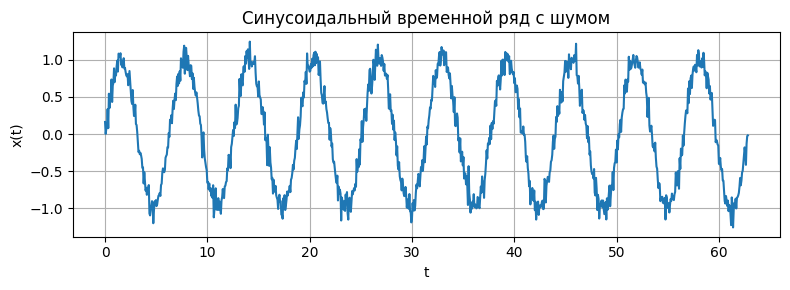

In [215]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

MY_SEED = 1
np.random.seed(MY_SEED)
torch.manual_seed(MY_SEED)

    
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

# Генерация синусоиды с шумом
n_points = 1000
t = np.linspace(0, 20 * np.pi, n_points)
signal = np.sin(t) + 0.1 * np.random.randn(n_points)

plt.figure(figsize=(8, 3))
plt.plot(t, signal)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Синусоидальный временной ряд с шумом")
plt.grid(True)
plt.tight_layout()
plt.show()

### Мини‑комментарий по ряду

Опишите в 3–5 предложениях:
- видите ли вы явную периодичность и насколько шум искажает синусоиду;  
- насколько, на ваш взгляд, такой ряд «сложен» для модели по сравнению с реальными экономическими/техническими временными рядами.


In [216]:
series_comment = """
1. Переодичность явно видна. Шум же достаточно искажает синусоиду. Особенно эти колебания заметны в минимумах и максимумах функции.
2. Думаю, экономические и технические временные ряды также редко бывают идеальными, всмысле без шумов.
Но на самой кривой слишком уж явно выражена переодичность, что упрощает работу для модели.
"""
print(series_comment)


1. Переодичность явно видна. Шум же достаточно искажает синусоиду. Особенно эти колебания заметны в минимумах и максимумах функции.
2. Думаю, экономические и технические временные ряды также редко бывают идеальными, всмысле без шумов.
Но на самой кривой слишком уж явно выражена переодичность, что упрощает работу для модели.



## 3. Нормализация и построение окон (скользящее окно)

Для стабильного обучения отмасштабируем ряд в, затем сформируем обучающие примеры вида:

- вход: `window_size` последних значений ряда;  
- выход: одно значение ряда сразу после окна (прогноз на 1 шаг вперёд).


In [217]:
scaler = MinMaxScaler(feature_range=(0, 1))
signal_scaled = scaler.fit_transform(signal.reshape(-1, 1)).flatten()

def create_windows(series, window_size):
    X = []
    y = []
    for i in range(len(series) - window_size):
        X.append(series[i:i+window_size])
        y.append(series[i+window_size])
    return np.array(X), np.array(y)

window_size = 20  # при своих экспериментах обязательно поменяйте и сравните
X_all, y_all = create_windows(signal_scaled, window_size)

print("Форма X_all:", X_all.shape)  # (n_samples, window_size)
print("Форма y_all:", y_all.shape)

Форма X_all: (980, 20)
Форма y_all: (980,)


Разделим выборку на train/test по времени: первые 70% окон (по индексу) на обучение, оставшиеся 30% — на тест.


In [218]:
train_size = int(0.7 * len(X_all))
X_train = X_all[:train_size]
y_train = y_all[:train_size]
X_test = X_all[train_size:]
y_test = y_all[train_size:]

print("Размер train:", X_train.shape)
print("Размер test :", X_test.shape)

Размер train: (686, 20)
Размер test : (294, 20)


Создадим `Dataset`/`DataLoader`. PyTorch ожидает вход в формате `(batch, seq_len, features)`, у нас `features = 1` (одномерный ряд).


In [219]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)  # (n, T, 1)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)  # (n, 1)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TimeSeriesDataset(X_train, y_train)
test_dataset = TimeSeriesDataset(X_test, y_test)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Кол-во батчей в train_loader:", len(train_loader))

Кол-во батчей в train_loader: 22


### Вопрос про размер окна

Ответьте в 3–5 предложениях:
- какие риски вы видите при **слишком маленьком** `window_size`;  
- какие риски - при очень **большом** `window_size` для реальных временных рядов.


In [220]:
window_comment = """
1. При слишком маленьком окне количество сэпмлов для анализа также будет маленьким, что не даст достаточного количества информации для модели.
2. При слишком большом окне, уже наоборот, данных станет настолько много, что уловить зависимость для следующего шага станет сложно.
"""
print(window_comment)


1. При слишком маленьком окне количество сэпмлов для анализа также будет маленьким, что не даст достаточного количества информации для модели.
2. При слишком большом окне, уже наоборот, данных станет настолько много, что уловить зависимость для следующего шага станет сложно.



## 4. Архитектура LSTM‑модели для прогноза

Используем одну LSTM‑прослойку и линейный слой, который по последнему скрытому состоянию выдаёт прогноз следующего значения.


In [221]:
input_size = 1
hidden_size = 32  # попробуйте другие значения при выполнении работы
num_layers = 1
output_size = 1

class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]  # (B, H)
        prediction = self.fc(last_hidden)  # (B, 1)
        return prediction

model = LSTMForecaster(input_size, hidden_size, num_layers, output_size).to(device)
print(model)

LSTMForecaster(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


### Мини‑комментарий по архитектуре

Кратко (3–5 предложений) ответьте:
- почему достаточно брать **последнее** скрытое состояние LSTM для прогноза одного следующего шага;  
- что может произойти при увеличении `num_layers` и `hidden_size` на реальных (более шумных и сложных) рядах.


In [222]:
arch_comment = """
1. Потому что последнее скрытое состояние LSTM уже является сжатым представлением всей предыдущей последовательности. 
2. Думаю, на шумных рядах увеличение num_layers и hidden_size приведет к переобучению. 
Модель начнет сильнее цепляться за шумы, вместо отслеживанния общих паттернов.
"""
print(arch_comment)


1. Потому что последнее скрытое состояние LSTM уже является сжатым представлением всей предыдущей последовательности. 
2. Думаю, на шумных рядах увеличение num_layers и hidden_size приведет к переобучению. 
Модель начнет сильнее цепляться за шумы, вместо отслеживанния общих паттернов.



## 5. Обучение: функция потерь, оптимизатор, цикл

Используем MSE (среднеквадратичную ошибку) и оптимизатор Adam.


In [223]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total = 0
    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        preds = model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)
        total += X_batch.size(0)

    return total_loss / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total = 0
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            total_loss += loss.item() * X_batch.size(0)
            total += X_batch.size(0)
    return total_loss / total

num_epochs = 30  # в своей работе попробуйте и другое число эпох
train_losses = []
test_losses = []

for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss = evaluate(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f"Эпоха {epoch}/{num_epochs}: train_loss={train_loss:.6f}, test_loss={test_loss:.6f}")

Эпоха 1/30: train_loss=0.183474, test_loss=0.105773
Эпоха 10/30: train_loss=0.002478, test_loss=0.002221
Эпоха 20/30: train_loss=0.002090, test_loss=0.001871
Эпоха 30/30: train_loss=0.002059, test_loss=0.001862


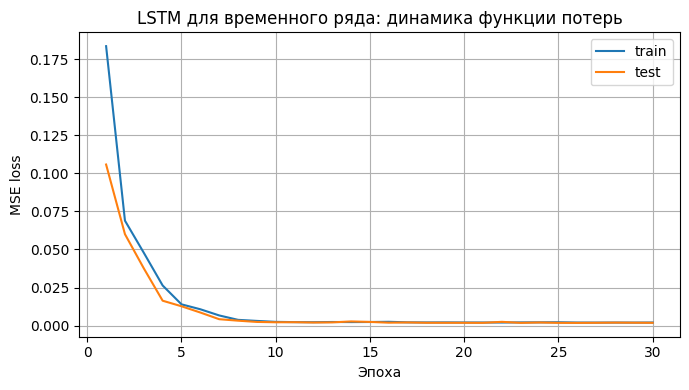

Финальные значения: train_loss=0.002059, test_loss=0.001862


In [224]:
epochs_arr = np.arange(1, num_epochs + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_arr, train_losses, label="train")
plt.plot(epochs_arr, test_losses, label="test")
plt.xlabel("Эпоха")
plt.ylabel("MSE loss")
plt.title("LSTM для временного ряда: динамика функции потерь")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Финальные значения: train_loss={train_losses[-1]:.6f}, test_loss={test_losses[-1]:.6f}")

### Анализ кривых обучения

Опишите (6–8 предложений):
- есть ли заметный разрыв между train и test loss к концу обучения;  
- похоже ли поведение на **устойчивое приближение** к некоторому уровню ошибки;  
- совпадает ли порядок величины ошибки с тем, что вы ожидали в начале работы.


In [225]:
loss_comment = """
1. Нет, разрыва нет, кривые сходятся примерно к 8 эпохе, не показывая далее заметного улучшения
2. Да, модель приближается к уровню loss = 0.001
3. Да, совпадает. Так как график - стандартная синусоида, такое низкое значение loss вполне ожидаемо.
"""
print(loss_comment)


1. Нет, разрыва нет, кривые сходятся примерно к 8 эпохе, не показывая далее заметного улучшения
2. Да, модель приближается к уровню loss = 0.001
3. Да, совпадает. Так как график - стандартная синусоида, такое низкое значение loss вполне ожидаемо.



## 6. Прогноз на один шаг вперёд (по всей тестовой части)

Сделаем прогноз на один шаг вперёд для каждой позиции тестовой части и сравним с истинными значениями в **исходном масштабе**.


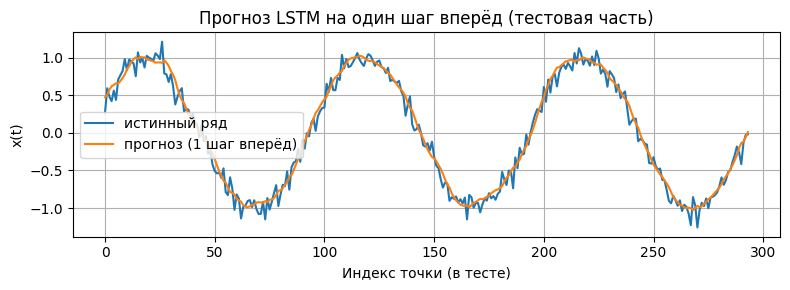

In [226]:
model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).unsqueeze(-1).to(device)
    preds_scaled = model(X_test_tensor).cpu().numpy().flatten()

y_test_scaled = y_test
y_test_orig = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).flatten()
preds_orig = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()

plt.figure(figsize=(8, 3))
plt.plot(range(len(y_test_orig)), y_test_orig, label="истинный ряд")
plt.plot(range(len(preds_orig)), preds_orig, label="прогноз (1 шаг вперёд)")
plt.xlabel("Индекс точки (в тесте)")
plt.ylabel("x(t)")
plt.title("Прогноз LSTM на один шаг вперёд (тестовая часть)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Визуальная оценка прогноза на один шаг

Ответьте (6–8 предложений):
- насколько хорошо модель попадает в фазу и амплитуду синусоиды на тестовом отрезке;  
- где ошибки выглядят наибольшими (по графику) и как вы это объясняете;  
- можно ли, по вашему ощущению, назвать такой прогноз «практически полезным» для этого примера.


In [227]:
one_step_comment = """
1. Модель отлично попадает в фазу и амплитуду на тестовом отрезке.
2. На всей кривой нет явных ошибок. Но если все-таки выбирать, то в областях минимума и максимума можно рассмотреть совсем небольшие неточности.
3. По моим ощущениям - да, можно.
"""
print(one_step_comment)


1. Модель отлично попадает в фазу и амплитуду на тестовом отрезке.
2. На всей кривой нет явных ошибок. Но если все-таки выбирать, то в областях минимума и максимума можно рассмотреть совсем небольшие неточности.
3. По моим ощущениям - да, можно.



## 7. Многошаговый авторегрессионный прогноз

Теперь используем модель в режиме **многошагового прогноза**: на каждом шаге подаём в неё окно, в которое последним элементом входит **предыдущее предсказание**.


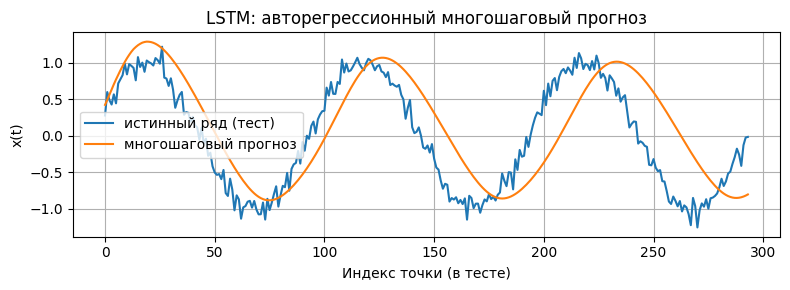

In [228]:
def multi_step_forecast(model, last_window, n_steps, device):
    model.eval()
    window = last_window.copy()
    preds = []
    with torch.no_grad():
        for _ in range(n_steps):
            x = torch.tensor(window, dtype=torch.float32).view(1, -1, 1).to(device)
            y_pred = model(x).cpu().numpy().flatten()
            y_scalar = float(y_pred[0])
            preds.append(y_scalar)
            window = np.roll(window, -1)
            window[-1] = y_scalar
    return np.array(preds)

# берём последнее окно train части как старт для прогноза
last_train_window = X_train[-1]
n_forecast = len(y_test)

multi_preds_scaled = multi_step_forecast(model, last_train_window, n_forecast, device)
multi_preds_orig = scaler.inverse_transform(multi_preds_scaled.reshape(-1, 1)).flatten()

plt.figure(figsize=(8, 3))
plt.plot(range(len(y_test_orig)), y_test_orig, label="истинный ряд (тест)")
plt.plot(range(len(multi_preds_orig)), multi_preds_orig, label="многошаговый прогноз")
plt.xlabel("Индекс точки (в тесте)")
plt.ylabel("x(t)")
plt.title("LSTM: авторегрессионный многошаговый прогноз")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Сравнение одношагового и многошагового прогноза

Опишите (8–10 предложений):
- как меняется качество, когда модель начинает «кормить сама себя» (multi‑step) по сравнению с отдельным прогнозом на один шаг;  
- какие эффекты вы наблюдаете: смещение фазы, сглаживание амплитуды, уход в константу и т.п.;  
- насколько эти эффекты совпадают с тем, что вы ожидали до эксперимента.


In [229]:
multi_step_comment = """
1. Качество ухудшается ввиду того, что ошибки накапливаются.
2. Практически сразу видно, что фаза начинает смещаться. Так же и уменьшается амплитуда. 
3. В целом это оправдано тем, что на многошаговом прогнозе с каждым следующим предсказанием ошибка становится больше, 
так как значение на входе уже включает в себя ошибки всех предыдущих предсказаний.
"""
print(multi_step_comment)


1. Качество ухудшается ввиду того, что ошибки накапливаются.
2. Практически сразу видно, что фаза начинает смещаться. Так же и уменьшается амплитуда. 
3. В целом это оправдано тем, что на многошаговом прогнозе с каждым следующим предсказанием ошибка становится больше, 
так как значение на входе уже включает в себя ошибки всех предыдущих предсказаний.



## 8. Идеи для вариаций в вашей работе

В **своём** варианте вы должны:

- попробовать как минимум **две дополнительные** конфигурации гиперпараметров (например, `window_size`, `hidden_size`, `num_layers`, `num_epochs`) и сравнить кривые loss и качество прогноза;  
- описать, какие конфигурации дают наилучший баланс между плавностью кривых, скоростью сходимости и качеством многошагового прогноза;  
- сформулировать практические «правила» выбора окна и размеров модели для похожих задач.


In [231]:
final_summary = """
1. Текущее значение window_size(20) является оптимальным. При других значениях (5 и 35) модель показала себя хуже. 
Различные вариации с hidden_size и num_layers (64 и 3, 32 и 5, 128 и 5) не дают модели прироста(хотя и расти почти некуда). 
В отдельных случаях (128 и 5) раздувание архитектуры привело к переобучению. 
Количество эпох также сократил с 80 до 30, так как начиная с 10 эпохи заметных улучшений почти не происходило. 
2. Наилучшей конфигурацией является hidden_size=32, num_layers=1, num_epochs=30, window_size=20. Она достаточна для достижения примелимых показателей loss.
3. Выбор размера окна зависит от количества входных данных, кривизны ряда.
Выбор модели зависит от входных данных, их формы и зашумленности 
"""
print(final_summary)


1. Текущее значение window_size(20) является оптимальным. При других значениях (5 и 35) модель показала себя хуже. 
Различные вариации с hidden_size и num_layers (64 и 3, 32 и 5, 128 и 5) не дают модели прироста(хотя и расти почти некуда). 
В отдельных случаях (128 и 5) раздувание архитектуры привело к переобучению. 
Количество эпох также сократил с 80 до 30, так как начиная с 10 эпохи заметных улучшений почти не происходило. 
2. Наилучшей конфигурацией является hidden_size=32, num_layers=1, num_epochs=30, window_size=20. Она достаточна для достижения примелимых показателей loss.
3. Выбор размера окна зависит от количества входных данных, кривизны ряда.
Выбор модели зависит от входных данных, их формы и зашумленности 

